# Phase 4 — Quantitative Evaluation, Error Analysis & Defense Material
**Northern (Pandan) / Southern (Virac) Catanduanes Bikol ↔ English — NLLB-200-distilled-600M + LoRA**

This notebook completes **Tasks 4.1 – 4.3** on the **held-out test set** (235 sentence trios = 1,410 sentence pairs over 6 directions).
It re-uses the exact decoding settings of Phase 2 (beam 4, max length 64, fp16 autocast) so test numbers are comparable with the validation numbers you already have.

| Task | Section | Output files (in `phase4_outputs/`) |
|---|---|---|
| **4.1** Automated metrics (BLEU / chrF++ / TER) | §3 | `test_metrics_by_direction.csv`, `test_predictions.csv`, bootstrap CIs |
| **4.2** Zero-shot vs. LoRA benchmark + latency table | §4 – §5 | `benchmark_table.csv`, `latency_*.csv`, `figures/*.png` |
| **4.3** Linguistic error analysis (30–50 sentences) | §6 | `error_analysis_sample.xlsx` (fill in) → `error_analysis_summary.csv` |
| Report | §7 | `Phase4_Report.md`, `phase4_results.json`, `phase4_outputs.zip` |

### How to run (Colab, T4 GPU)
1. **Runtime → Change runtime type → T4 GPU.**
2. Run the cells top to bottom. When asked, upload **`Bikole_Phase3.zip`** (it contains `models/lora_adapter` *and* the Phase 3 API code used for the end-to-end check in §5b).
   Alternatives: put `lora_adapter/` in the Colab file panel, or set `HF_ADAPTER_REPO` in the config cell.
3. The test set and the training vocabulary are **embedded in this notebook** (cell “Embedded data”), so no other upload is needed.
4. Total runtime on a T4 ≈ 20–30 min (the two decoding passes ≈ 5 min, bootstrap ≈ 3–6 min, latency ≈ 4 min, API check ≈ 8 min).

> ⚠️ The test set must be used **once, for reporting**. Do not tune anything on it. (Model selection in Phase 2 used the validation set only.)

## 0. Setup

In [1]:
#@SKIP_TEST
!pip -q uninstall -y torchao
!pip -q install -U peft accelerate sacrebleu sentencepiece openpyxl scipy

In [2]:
import os, re, io, sys, json, gzip, base64, copy, gc, time, math, glob, zipfile, shutil, warnings, collections, hashlib
from difflib import SequenceMatcher
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
try: display
except NameError: display = print
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 200)

# =============================== CONFIG ===============================
SEED            = 42
MODEL_NAME      = "facebook/nllb-200-distilled-600M"
CODE            = {"eng": "eng_Latn", "bcl_North": "tgl_Latn", "bcl_South": "war_Latn"}   # proxy tags (same as Phase 2)
DIRECTIONS      = [("bcl_North", "eng"), ("eng", "bcl_North"), ("bcl_South", "eng"),
                   ("eng", "bcl_South"), ("bcl_South", "bcl_North"), ("bcl_North", "bcl_South")]
MAX_LEN         = 64          # same as training
NUM_BEAMS       = 4           # same as Phase 2 evaluation and the Phase 3 API default
BOOT_N          = 300         # bootstrap resamples for CIs / paired significance (raise to 1000 for the final run if time allows)
N_ERRORS        = 50          # Task 4.3: 30-50 mistranslated sentences
ERR_CHRF_MAX    = 50.0        # a sentence counts as "mistranslated" if its sentence-level chrF++ is below this (and it is not an exact match)
LAT_PER_BUCKET  = 40          # latency: sentences timed per source-length bucket
RUN_CPU_LATENCY = False       # optional (slow): also time an fp32 CPU copy on 5 sentences/bucket
RUN_API_PARITY  = True        # §5b: push the test set through the real Phase 3 engine (needs the Phase 3 zip)
HF_ADAPTER_REPO = None        # e.g. "your-username/nllb-bikol-lora" if you pushed the adapter to the Hub
OUT_DIR         = "phase4_outputs"
LATENCY_TARGET_MS = 300       # rubric target
# ======================================================================
os.makedirs(f"{OUT_DIR}/figures", exist_ok=True)
rng = np.random.default_rng(SEED)
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
DIR_LABEL = lambda d: f"{d[0]} → {d[1]}"
print("Colab:", IN_COLAB, "| directions:", len(DIRECTIONS))

Colab: True | directions: 6


## 1. Test data (embedded)
The cell below holds, compressed, **(a)** the 235 held-out test trios produced by the Phase 1 notebook (seed 42, leakage-grouped 70/15/15 split) and **(b)** the word vocabulary of the *training* split per language (only used in §6 to flag source words the model never saw during fine-tuning).

In [3]:
#@DATA
DATA_B64 = '''
...
'''

In [4]:
PAYLOAD = json.loads(gzip.decompress(base64.b64decode("".join(DATA_B64.split()))))
test_rows   = PAYLOAD["test"]
TRAIN_VOCAB = {l: set(v) for l, v in PAYLOAD["train_vocab"].items()}
assert len(test_rows) == 235 and PAYLOAD["n_train"] == 1098, "unexpected split sizes - this is not the Phase 1 split"

TEST_BY_DIR = {(s, t): [{"id": r["id"], "src": r[s], "tgt": r[t]} for r in test_rows] for s, t in DIRECTIONS}
REFS = {d: [x["tgt"] for x in TEST_BY_DIR[d]] for d in DIRECTIONS}
SRCS = {d: [x["src"] for x in TEST_BY_DIR[d]] for d in DIRECTIONS}

# integrity: nothing in the test set may occur in the training vocabulary *as a whole sentence* (Phase 1 already asserted this on the full data)
WORD_RE = re.compile(r"[^\W\d_]+(?:['\-][^\W\d_]+)*", re.UNICODE)
toks = lambda s: [w.lower() for w in WORD_RE.findall(str(s))]
print(f"Test sentences per direction: {len(test_rows)}  | directions: {len(DIRECTIONS)}  | total test pairs: {len(test_rows)*len(DIRECTIONS)}")
print("Test-set fingerprint (sha1 of all English test sentences):", hashlib.sha1("\n".join(r['eng'] for r in test_rows).encode()).hexdigest()[:12])

stat = []
for l in ["eng", "bcl_South", "bcl_North"]:
    w = [len(toks(r[l])) for r in test_rows]; tk = [t for r in test_rows for t in toks(r[l])]
    oov = np.mean([t not in TRAIN_VOCAB[l] for t in tk]) * 100
    stat.append({"language": l, "sentences": len(w), "mean words": np.mean(w), "max words": max(w), "tokens": len(tk), "test→train OOV token %": oov})
test_stats = pd.DataFrame(stat); display(test_stats.round(2))
display(pd.DataFrame(test_rows)[["id", "eng", "bcl_South", "bcl_North"]].head(6))

Test sentences per direction: 235  | directions: 6  | total test pairs: 1410
Test-set fingerprint (sha1 of all English test sentences): 22e849602216


,language,sentences,mean words,max words,tokens,test→train OOV token %
0,eng,235,6.51,16,1529,15.57
1,bcl_South,235,7.00,19,1645,16.90
2,bcl_North,235,6.77,19,1591,17.10


,id,eng,bcl_South,bcl_North
0,3,Is the rice cooked already?,Unog na ba so maluto?,Unog na yu humay?
1,16,Get your dad from the drinking session.,Susudon mo ama mo duman sa inuman.,Susuda daw dun si ama mo sa inuman.
2,18,I'll slap you!,Sapakon ta ka!,Rapaduhon ta ka!
3,34,You should exercise because your belly is getting bigger.,Mag exercise ka ta ang tulak mo gapay dakula.,Pag exercise ngani ta yang tindos mo gaparsarig.
4,62,I don't feel like walking.,Nakangalas maglakaw.,Naharang ako magpanaw.
5,65,Cover the food on the table or the cat will eat it.,Takpan mo daw so pagkaon ta tibaad kaunon ning kuting.,Takpuran mo yu pagkaon sa lamesa ta kung mai kakaunon yan ning kurasmag.


## 2. Load the adapter and the models

In [5]:
#@MODEL
# ---- locate the LoRA adapter (folder containing adapter_config.json) ----
CANDIDATES = ["lora_adapter", "phase2_outputs/multi/lora_adapter", "bikole/models/lora_adapter",
              "Bikole_Phase3/bikole/models/lora_adapter", "/content/drive/MyDrive/bikol_nmt/phase2_outputs/multi/lora_adapter"]
def find_adapter():
    for c in CANDIDATES:
        if os.path.exists(f"{c}/adapter_config.json"): return c
    hits = glob.glob("**/lora_adapter/adapter_config.json", recursive=True) + glob.glob("**/adapter_config.json", recursive=True)
    return os.path.dirname(hits[0]) if hits else None

ADAPTER_DIR = find_adapter()
if ADAPTER_DIR is None and HF_ADAPTER_REPO:
    from huggingface_hub import snapshot_download
    ADAPTER_DIR = snapshot_download(HF_ADAPTER_REPO)
if ADAPTER_DIR is None and IN_COLAB:
    print("Upload Bikole_Phase3.zip (or a zip of the lora_adapter folder) ...")
    up = files.upload()
    for name in up:
        if name.endswith(".zip"):
            with zipfile.ZipFile(name) as z: z.extractall(".")
    ADAPTER_DIR = find_adapter()
assert ADAPTER_DIR, "Adapter not found: upload Bikole_Phase3.zip, place lora_adapter/ next to the notebook, or set HF_ADAPTER_REPO."
meta = json.load(open(f"{ADAPTER_DIR}/bikol_meta.json")) if os.path.exists(f"{ADAPTER_DIR}/bikol_meta.json") else {}
print("Adapter:", ADAPTER_DIR)
print("Adapter metadata:", json.dumps({k: meta.get(k) for k in ("base_model", "run_name", "lora", "training")}, indent=1)[:900])
assert meta.get("base_model", MODEL_NAME) == MODEL_NAME and meta.get("language_code_map", CODE) == CODE, "adapter was trained with different model / language tags"

Upload Bikole_Phase3.zip (or a zip of the lora_adapter folder) ...


Saving lora_adapter.zip to lora_adapter.zip
Adapter: lora_adapter
Adapter metadata: {
 "base_model": "facebook/nllb-200-distilled-600M",
 "run_name": "multi",
 "lora": {
  "r": 32,
  "alpha": 64,
  "dropout": 0.2,
  "target_modules": [
   "q_proj",
   "k_proj",
   "v_proj",
   "out_proj",
   "fc1",
   "fc2"
  ]
 },
 "training": {
  "lr": 0.0002,
  "epochs": 30,
  "batch_size": 16,
  "seed": 42,
  "best_epoch": 18,
  "best_val_BLEU": 23.34961733514427,
  "label_smoothing": 0.15,
  "src_token_dropout": 0.1,
  "weight_decay": 0.05,
  "lora_dropout": 0.2,
  "best_val_loss": 2.1338260173797607
 }
}


In [6]:
#@MODEL
import torch, transformers, peft
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, set_seed
from peft import PeftModel
transformers.logging.set_verbosity_error(); set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"torch {torch.__version__} | transformers {transformers.__version__} | peft {peft.__version__} | device: {DEVICE}",
      torch.cuda.get_device_name(0) if DEVICE == "cuda" else "(no GPU: decoding will be slow, latency numbers will not be representative)")
tokenizer = AutoTokenizer.from_pretrained(ADAPTER_DIR)

@torch.no_grad()
def translate(model, texts, src_lang, tgt_lang, num_beams=NUM_BEAMS, bs=32, max_new_tokens=96, device=None, amp_on=True):
    # identical to the Phase 2 evaluation function
    device = device or DEVICE
    model.eval()
    tokenizer.src_lang = CODE[src_lang]
    forced = tokenizer.convert_tokens_to_ids(CODE[tgt_lang])
    order = np.argsort([-len(t) for t in texts]); out = [None] * len(texts)
    for i in range(0, len(texts), bs):
        idx = order[i:i + bs]
        enc = tokenizer([texts[j] for j in idx], return_tensors="pt", padding=True, truncation=True, max_length=MAX_LEN).to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=(amp_on and device == "cuda")):
            gen = model.generate(**enc, forced_bos_token_id=forced, num_beams=num_beams, max_new_tokens=max_new_tokens)
        for j, d in zip(idx, tokenizer.batch_decode(gen, skip_special_tokens=True)): out[j] = d
    return out

def decode_all(model, label, **kw):
    hyps = {}
    for d in DIRECTIONS:
        t0 = time.time(); hyps[d] = translate(model, SRCS[d], d[0], d[1], **kw)
        print(f"  {label:<14} {DIR_LABEL(d):<24} {len(hyps[d])} sentences in {time.time()-t0:5.1f}s")
    return hyps

torch 2.14.1+cu130 | transformers 5.22.1 | peft 0.21.3 | device: cuda Tesla T4


## 3. Task 4.1 — Automated metric evaluation on the held-out test set
Metrics (SacreBLEU): **BLEU** (13a tokenisation, exp smoothing), **chrF++** (`word_order=2`), **TER**. Higher is better for BLEU/chrF++, **lower for TER**.
Systems: (1) **zero-shot** NLLB-600M (un-tuned; Pandan tagged `tgl_Latn`, Virac tagged `war_Latn`, English `eng_Latn`), (2) **LoRA** fine-tuned adapter, plus a trivial **copy-source** reference for the two Bikol↔Bikol directions.

In [7]:
#@MODEL
# ---- zero-shot baseline: the un-tuned base model ----
base = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(DEVICE).eval()
ZS_HYPS = decode_all(base, "zero-shot")
del base; gc.collect(); torch.cuda.empty_cache()

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.46GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

  zero-shot      bcl_North → eng          235 sentences in   7.5s
  zero-shot      eng → bcl_North          235 sentences in  10.3s
  zero-shot      bcl_South → eng          235 sentences in   9.3s
  zero-shot      eng → bcl_South          235 sentences in   7.2s
  zero-shot      bcl_South → bcl_North    235 sentences in   5.3s
  zero-shot      bcl_North → bcl_South    235 sentences in   5.2s


In [8]:
#@MODEL
# ---- LoRA model: base + adapter, merged for fast inference (this is what the Phase 3 API serves) ----
lora = PeftModel.from_pretrained(AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME), ADAPTER_DIR).merge_and_unload().to(DEVICE).eval()
FT_HYPS = decode_all(lora, "LoRA")

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

  LoRA           bcl_North → eng          235 sentences in   5.6s
  LoRA           eng → bcl_North          235 sentences in   6.0s
  LoRA           bcl_South → eng          235 sentences in   5.3s
  LoRA           eng → bcl_South          235 sentences in   6.6s
  LoRA           bcl_South → bcl_North    235 sentences in   6.2s
  LoRA           bcl_North → bcl_South    235 sentences in   6.0s


In [9]:
from sacrebleu.metrics import BLEU, CHRF, TER
_bleu, _chrf, _ter = BLEU(), CHRF(word_order=2), TER()
METRICS = ["BLEU", "chrF++", "TER"]
def score(hyps, refs):
    return {"BLEU": _bleu.corpus_score(hyps, [refs]).score, "chrF++": _chrf.corpus_score(hyps, [refs]).score,
            "TER": _ter.corpus_score(hyps, [refs]).score}
def sent_chrf(h, r): return _chrf.sentence_score(h, [r]).score
def signatures():
    out = {}
    for n, m in (("BLEU", _bleu), ("chrF++", _chrf), ("TER", _ter)):
        try: out[n] = str(m.get_signature())
        except Exception: out[n] = "n/a"
    return out

def boot(hyps_by_sys, refs, n=BOOT_N, seed=SEED):
    # paired bootstrap over test sentences: the SAME resampled sentences are scored for every system
    rs = np.random.default_rng(seed); N = len(refs)
    vals = {k: {m: [] for m in METRICS} for k in hyps_by_sys}
    for _ in range(n):
        idx = rs.integers(0, N, N); R = [refs[i] for i in idx]
        for k, h in hyps_by_sys.items():
            sc = score([h[i] for i in idx], R)
            for m in METRICS: vals[k][m].append(sc[m])
    return {k: {m: np.array(v) for m, v in mv.items()} for k, mv in vals.items()}

ZS, FT = ZS_HYPS, FT_HYPS
num_rows, BOOT = [], {}
for d in DIRECTIONS:
    BOOT[d] = boot({"zs": ZS[d], "ft": FT[d]}, REFS[d]); print("bootstrap done:", DIR_LABEL(d))
    for key, label, H in (("zs", "Zero-shot NLLB-600M", ZS), ("ft", "LoRA fine-tuned", FT)):
        sc = score(H[d], REFS[d])
        row = {"direction": DIR_LABEL(d), "system": label, "n": len(REFS[d]), **sc}
        for m in METRICS:
            lo, hi = np.percentile(BOOT[d][key][m], [2.5, 97.5]); row[f"{m} lo"], row[f"{m} hi"] = lo, hi
        num_rows.append(row)
num_tbl = pd.DataFrame(num_rows)

# copy-source reference for the dialect<->dialect directions (can the model beat "do nothing"?)
copy_rows = []
for d in DIRECTIONS:
    if "eng" not in d: copy_rows.append({"direction": DIR_LABEL(d), "system": "Copy source (no translation)", "n": len(REFS[d]), **score(SRCS[d], REFS[d])})
copy_tbl = pd.DataFrame(copy_rows)

def cell(r, m): return f"{r[m]:.1f} [{r[m+' lo']:.1f}–{r[m+' hi']:.1f}]"
main_tbl = pd.DataFrame([{"Direction": r["direction"], "System": r["system"], "n": r["n"], **{m: cell(r, m) for m in METRICS}}
                         for _, r in num_tbl.iterrows()])
print("\nTable 4.1 — TEST-set metrics (point estimate [95 % bootstrap CI], 235 sentences per direction)")
display(main_tbl)
print("\nCopy-source reference (Bikol↔Bikol):"); display(copy_tbl.round(2))
SIGS = signatures(); print("\nSacreBLEU signatures:", SIGS)

num_tbl.to_csv(f"{OUT_DIR}/test_metrics_by_direction.csv", index=False); copy_tbl.to_csv(f"{OUT_DIR}/test_copy_baseline.csv", index=False)
pred_rows = []
for d in DIRECTIONS:
    for i, x in enumerate(TEST_BY_DIR[d]):
        pred_rows.append({"direction": DIR_LABEL(d), "test_id": x["id"], "source": x["src"], "reference": x["tgt"], "zero_shot": ZS[d][i], "lora": FT[d][i],
                          "chrF++_zero_shot": sent_chrf(ZS[d][i], x["tgt"]), "chrF++_lora": sent_chrf(FT[d][i], x["tgt"])})
preds_df = pd.DataFrame(pred_rows); preds_df.to_csv(f"{OUT_DIR}/test_predictions.csv", index=False, encoding="utf-8")
print("Saved test_predictions.csv:", len(preds_df), "rows")

bootstrap done: bcl_North → eng
bootstrap done: eng → bcl_North
bootstrap done: bcl_South → eng
bootstrap done: eng → bcl_South
bootstrap done: bcl_South → bcl_North
bootstrap done: bcl_North → bcl_South

Table 4.1 — TEST-set metrics (point estimate [95 % bootstrap CI], 235 sentences per direction)


,Direction,System,n,BLEU,chrF++,TER
0,bcl_North → eng,Zero-shot NLLB-600M,235,11.2 [8.6–13.7],31.8 [29.3–34.6],87.6 [83.3–91.2]
1,bcl_North → eng,LoRA fine-tuned,235,29.2 [25.8–32.8],46.6 [43.6–50.0],59.0 [55.0–63.4]
2,eng → bcl_North,Zero-shot NLLB-600M,235,3.5 [2.0–5.1],28.2 [26.7–29.8],99.2 [95.2–102.7]
3,eng → bcl_North,LoRA fine-tuned,235,21.3 [18.5–24.3],46.8 [44.7–49.2],63.5 [60.1–66.8]
4,bcl_South → eng,Zero-shot NLLB-600M,235,15.7 [12.6–19.1],36.6 [33.9–39.3],87.1 [77.4–99.4]
5,bcl_South → eng,LoRA fine-tuned,235,30.0 [26.2–33.5],47.3 [44.4–50.1],56.2 [52.5–59.8]
6,eng → bcl_South,Zero-shot NLLB-600M,235,1.8 [1.0–2.7],24.8 [23.6–25.8],100.7 [97.9–103.9]
7,eng → bcl_South,LoRA fine-tuned,235,19.6 [16.6–23.0],45.3 [43.1–47.7],65.3 [61.7–68.5]
8,bcl_South → bcl_North,Zero-shot NLLB-600M,235,3.2 [1.9–4.5],27.3 [25.9–28.9],97.7 [94.7–101.3]
9,bcl_South → bcl_North,LoRA fine-tuned,235,26.7 [23.3–30.2],51.0 [48.7–53.5],57.4 [53.4–60.9]



Copy-source reference (Bikol↔Bikol):


,direction,system,n,BLEU,chrF++,TER
0,bcl_South → bcl_North,Copy source (no translation),235,18.01,47.31,67.04
1,bcl_North → bcl_South,Copy source (no translation),235,18.13,46.95,64.85



SacreBLEU signatures: {'BLEU': 'nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0', 'chrF++': 'nrefs:1|case:mixed|eff:yes|nc:6|nw:2|space:no|version:2.6.0', 'TER': 'nrefs:1|case:lc|tok:tercom|norm:no|punct:yes|asian:no|version:2.6.0'}
Saved test_predictions.csv: 1410 rows


## 4. Task 4.2 — Benchmark comparison: zero-shot baseline vs. LoRA fine-tuned
Significance is a **paired bootstrap** over the test sentences (both systems are scored on the same resamples). `p` is the share of resamples in which LoRA was *not* better than zero-shot.
The last columns re-state the **validation** scores from Phase 2 so you can show that the gains hold on unseen data (the adapter was selected on validation, so the test set is the unbiased number).

,Direction,BLEU zero-shot,BLEU LoRA,ΔBLEU,p(BLEU),chrF++ zero-shot,chrF++ LoRA,ΔchrF++,p(chrF++),TER zero-shot,TER LoRA,ΔTER,p(TER),val BLEU (LoRA),val chrF++ (LoRA),val TER (LoRA)
0,bcl_North → eng,11.199,29.195,17.997,0.0,31.805,46.592,14.788,0.0,87.590,59.046,-28.543,0.0,27.410,45.040,63.790
1,eng → bcl_North,3.537,21.306,17.768,0.0,28.172,46.834,18.662,0.0,99.247,63.528,-35.719,0.0,21.470,45.880,67.200
2,bcl_South → eng,15.668,30.018,14.350,0.0,36.577,47.343,10.765,0.0,87.067,56.238,-30.830,0.0,27.230,46.760,59.610
3,eng → bcl_South,1.818,19.600,17.782,0.0,24.779,45.321,20.542,0.0,100.668,65.270,-35.398,0.0,21.330,45.140,64.520
4,bcl_South → bcl_North,3.217,26.656,23.439,0.0,27.317,50.998,23.681,0.0,97.740,57.376,-40.364,0.0,25.160,50.290,60.990
5,bcl_North → bcl_South,1.513,23.938,22.425,0.0,23.611,50.038,26.426,0.0,103.825,59.077,-44.748,0.0,24.230,47.940,62.930
6,MEAN of 6 directions,6.159,25.119,18.960,NaN,28.710,47.854,19.144,NaN,96.023,60.089,-35.934,NaN,24.472,46.842,63.173
7,mean: → English (Bikol→eng),13.433,29.607,16.173,NaN,34.191,46.967,12.776,NaN,87.329,57.642,-29.686,NaN,27.320,45.900,61.700
8,mean: → Bikol (eng→Bikol),2.678,20.453,17.775,NaN,26.475,46.077,19.602,NaN,99.957,64.399,-35.558,NaN,21.400,45.510,65.860
9,mean: Dialect↔dialect,2.365,25.297,22.932,NaN,25.464,50.518,25.054,NaN,100.783,58.227,-42.556,NaN,24.695,49.115,61.960


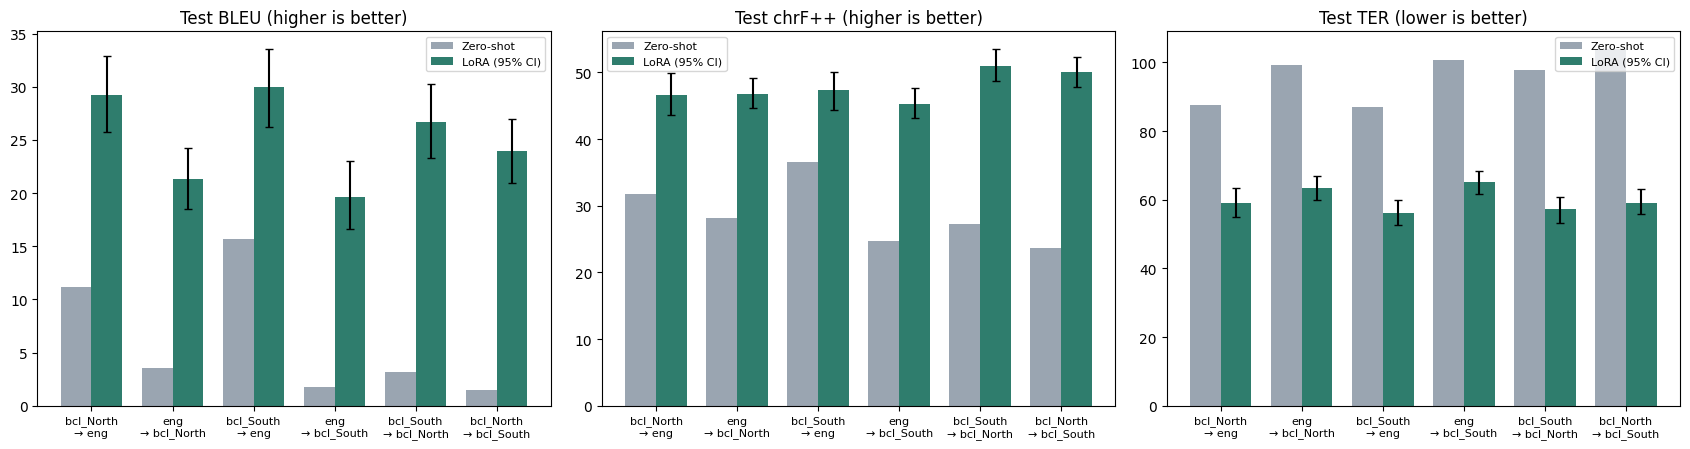

bcl_South → bcl_North: copy-source chrF++ 47.3 / BLEU 18.0  vs LoRA chrF++ 51.0 / BLEU 26.7  -> only a small chrF++ margin over simply copying the source (the two dialects share most of their words)
bcl_North → bcl_South: copy-source chrF++ 47.0 / BLEU 18.1  vs LoRA chrF++ 50.0 / BLEU 23.9  -> only a small chrF++ margin over simply copying the source (the two dialects share most of their words)


In [10]:
# validation results copied from the Phase 2 notebook (cell 2.3c, 236 sentences/direction, beam 4)
VAL = {  # direction: (zs BLEU, zs chrF++, zs TER, lora BLEU, lora chrF++, lora TER)
    ("bcl_North", "eng"):       (12.08, 32.81,  86.80, 27.41, 45.04, 63.79),
    ("eng", "bcl_North"):       ( 3.97, 27.30, 100.81, 21.47, 45.88, 67.20),
    ("bcl_South", "eng"):       (15.91, 36.44,  80.92, 27.23, 46.76, 59.61),
    ("eng", "bcl_South"):       ( 1.68, 25.35,  98.47, 21.33, 45.14, 64.52),
    ("bcl_South", "bcl_North"): ( 4.06, 27.22,  98.51, 25.16, 50.29, 60.99),
    ("bcl_North", "bcl_South"): ( 2.66, 24.44, 102.30, 24.23, 47.94, 62.93),
}
rows = []
for d in DIRECTIONS:
    z = num_tbl[(num_tbl.direction == DIR_LABEL(d)) & num_tbl.system.str.startswith("Zero")].iloc[0]
    f = num_tbl[(num_tbl.direction == DIR_LABEL(d)) & num_tbl.system.str.startswith("LoRA")].iloc[0]
    b = BOOT[d]; r = {"Direction": DIR_LABEL(d)}
    for m in METRICS:
        gain = (b["zs"][m] - b["ft"][m]) if m == "TER" else (b["ft"][m] - b["zs"][m])    # positive = LoRA better
        r[f"{m} zero-shot"], r[f"{m} LoRA"] = z[m], f[m]
        r[f"Δ{m}"] = (f[m] - z[m]); r[f"p({m})"] = float((gain <= 0).mean())
    v = VAL[d]; r["val BLEU (LoRA)"], r["val chrF++ (LoRA)"], r["val TER (LoRA)"] = v[3], v[4], v[5]
    rows.append(r)
bench_tbl = pd.DataFrame(rows)
macro = {"Direction": "MEAN of 6 directions"}
for c in bench_tbl.columns[1:]: macro[c] = bench_tbl[c].mean() if not c.startswith("p(") else np.nan
groups = {"→ English (Bikol→eng)": [0, 2], "→ Bikol (eng→Bikol)": [1, 3], "Dialect↔dialect": [4, 5]}
grp_rows = []
for g, ix in groups.items():
    r = {"Direction": f"mean: {g}"}
    for c in bench_tbl.columns[1:]: r[c] = bench_tbl[c].iloc[ix].mean() if not c.startswith("p(") else np.nan
    grp_rows.append(r)
bench_full = pd.concat([bench_tbl, pd.DataFrame([macro] + grp_rows)], ignore_index=True)
display(bench_full.round(3)); bench_full.to_csv(f"{OUT_DIR}/benchmark_table.csv", index=False)

# figure: grouped bars with LoRA 95% CI
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
x = np.arange(len(DIRECTIONS)); w = 0.38
for ax, m in zip(axes, METRICS):
    zs_v = [num_tbl[(num_tbl.direction == DIR_LABEL(d)) & num_tbl.system.str.startswith("Zero")][m].iloc[0] for d in DIRECTIONS]
    ft_r = [num_tbl[(num_tbl.direction == DIR_LABEL(d)) & num_tbl.system.str.startswith("LoRA")].iloc[0] for d in DIRECTIONS]
    ft_v = [r[m] for r in ft_r]; err = [[r[m] - r[f"{m} lo"] for r in ft_r], [r[f"{m} hi"] - r[m] for r in ft_r]]
    ax.bar(x - w/2, zs_v, w, label="Zero-shot", color="#9aa5b1"); ax.bar(x + w/2, ft_v, w, yerr=err, capsize=3, label="LoRA (95% CI)", color="#2f7d6d")
    ax.set_xticks(x); ax.set_xticklabels([DIR_LABEL(d).replace(" → ", "\n→ ") for d in DIRECTIONS], fontsize=8)
    ax.set_title(f"Test {m} " + ("(lower is better)" if m == "TER" else "(higher is better)")); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figures/test_zero_shot_vs_lora.png", dpi=150); plt.show()

# is the model better than doing nothing between the two dialects?
for _, c in copy_tbl.iterrows():
    f = num_tbl[(num_tbl.direction == c.direction) & num_tbl.system.str.startswith("LoRA")].iloc[0]
    print(f"{c.direction}: copy-source chrF++ {c['chrF++']:.1f} / BLEU {c.BLEU:.1f}  vs LoRA chrF++ {f['chrF++']:.1f} / BLEU {f.BLEU:.1f}  "
          f"-> {'LoRA clearly better' if f['chrF++'] - c['chrF++'] > 5 else 'only a small chrF++ margin over simply copying the source (the two dialects share most of their words)'}")

### 4b. Latency analysis (inference time vs. input length)
Single-sentence requests (what a web client sends), timed from tokenisation to decoded text, after warm-up, with CUDA synchronisation.
Two deployable variants of the **merged** LoRA model are compared: **B = fp32 + autocast** (what `backend/nmt/engine.py` loads by default) and **C = fp16**, each with greedy and beam-4 decoding.
Length = number of NLLB sub-word tokens of the source sentence. Target: **< 300 ms**.

Test sources per length bucket: {'≤6': 226, '7–10': 620, '11–14': 314, '15–20': 170, '>20': 80}
timed B: merged fp32 + AMP (API default)
timed C: merged fp16
Table 4.4a — latency summary (ms per single-sentence request; target < 300 ms)


,variant,mode,n,mean_ms,median_ms,p95_ms,pct_under_target,ms_per_out_token
0,B: merged fp32 + AMP (API default),beam4,200,417.2,372.7,738.7,28.0,27.6
1,B: merged fp32 + AMP (API default),greedy,200,369.2,332.5,649.5,40.5,24.1
2,C: merged fp16,beam4,200,245.9,223.4,416.8,73.0,16.2
3,C: merged fp16,greedy,200,211.0,185.3,396.8,83.0,13.8


Table 4.4b — mean latency (ms) by source length in NLLB tokens


bucket                                        ≤6   7–10  11–14  15–20    >20
variant                            mode                                     
B: merged fp32 + AMP (API default) beam4   256.0  335.0  389.0  517.0  590.0
                                   greedy  211.0  305.0  342.0  463.0  524.0
C: merged fp16                     beam4   151.0  201.0  230.0  301.0  345.0
                                   greedy  126.0  173.0  197.0  256.0  302.0

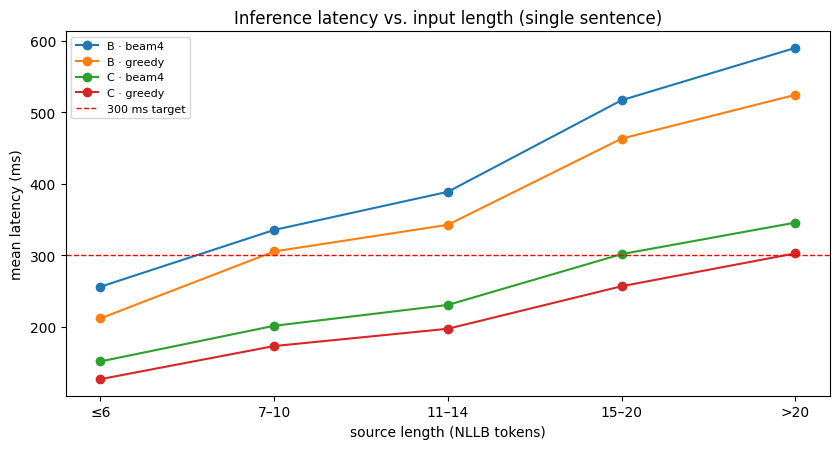

In [11]:
#@MODEL
BUCKETS, BLABELS = [0, 6, 10, 14, 20, 1000], ["≤6", "7–10", "11–14", "15–20", ">20"]
pool = []
for d in DIRECTIONS:
    tokenizer.src_lang = CODE[d[0]]
    for x in TEST_BY_DIR[d]:
        pool.append({"s": d[0], "t": d[1], "text": x["src"], "src_tokens": len(tokenizer(x["src"], add_special_tokens=False)["input_ids"])})
pool = pd.DataFrame(pool); pool["bucket"] = pd.cut(pool.src_tokens, BUCKETS, labels=BLABELS)
print("Test sources per length bucket:", pool.bucket.value_counts().reindex(BLABELS).to_dict())

def time_one(model, text, s, t, beams, device, amp):
    tokenizer.src_lang = CODE[s]; forced = tokenizer.convert_tokens_to_ids(CODE[t])
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    enc = tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(device)
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=(amp and device == "cuda")):
        g = model.generate(**enc, forced_bos_token_id=forced, num_beams=beams, max_new_tokens=96)
    _ = tokenizer.decode(g[0], skip_special_tokens=True)
    if device == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) * 1000, int(g.shape[1])

def bench_variant(name, model, device, amp, per_bucket):
    recs = []
    sample = pd.concat([g.sample(min(per_bucket, len(g)), random_state=SEED) for _, g in pool.groupby("bucket", observed=True)])
    sample = sample.sample(frac=1, random_state=SEED)                      # mix lengths so warm-up is not biased to the shortest bucket
    for beams, mode in ((1, "greedy"), (NUM_BEAMS, f"beam{NUM_BEAMS}")):
        for _, r in sample.head(3).iterrows(): time_one(model, r.text, r.s, r.t, beams, device, amp)        # warm-up
        for _, r in sample.iterrows():
            ms, n_out = time_one(model, r.text, r.s, r.t, beams, device, amp)
            recs.append({"variant": name, "mode": mode, "src_tokens": r.src_tokens, "bucket": r.bucket, "out_tokens": n_out, "ms": ms})
    print(f"timed {name}"); return pd.DataFrame(recs)

lat_parts = []
lat_parts.append(bench_variant("B: merged fp32 + AMP (API default)", lora, DEVICE, True, LAT_PER_BUCKET))
lora16 = copy.deepcopy(lora).half().eval()
lat_parts.append(bench_variant("C: merged fp16", lora16, DEVICE, False, LAT_PER_BUCKET))
del lora16; gc.collect(); torch.cuda.empty_cache()
if RUN_CPU_LATENCY:
    cpu_m = copy.deepcopy(lora).float().cpu().eval()
    lat_parts.append(bench_variant("D: merged fp32 (CPU)", cpu_m, "cpu", False, 5)); del cpu_m
lat = pd.concat(lat_parts, ignore_index=True); lat["bucket"] = pd.Categorical(lat.bucket, BLABELS, ordered=True)
lat.to_csv(f"{OUT_DIR}/latency_raw.csv", index=False)

lat_summary = lat.groupby(["variant", "mode"]).agg(n=("ms", "size"), mean_ms=("ms", "mean"), median_ms=("ms", "median"),
                                                     p95_ms=("ms", lambda s: s.quantile(.95)), pct_under_target=("ms", lambda s: 100 * (s < LATENCY_TARGET_MS).mean()),
                                                     ms_sum=("ms", "sum"), out_sum=("out_tokens", "sum")).reset_index()
lat_summary["ms_per_out_token"] = lat_summary.ms_sum / lat_summary.out_sum; lat_summary = lat_summary.drop(columns=["ms_sum", "out_sum"])
lat_by_len = lat.pivot_table(index=["variant", "mode"], columns="bucket", values="ms", aggfunc="mean", observed=True).round(0)
print(f"Table 4.4a — latency summary (ms per single-sentence request; target < {LATENCY_TARGET_MS} ms)"); display(lat_summary.round(1))
print("Table 4.4b — mean latency (ms) by source length in NLLB tokens"); display(lat_by_len)
lat_summary.to_csv(f"{OUT_DIR}/latency_summary.csv", index=False); lat_by_len.to_csv(f"{OUT_DIR}/latency_by_length.csv")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
for (v, m), g in lat.groupby(["variant", "mode"]):
    s = g.groupby("bucket", observed=True).ms.mean(); ax.plot(range(len(s)), s.values, "o-", label=f"{v.split(':')[0]} · {m}")
ax.axhline(LATENCY_TARGET_MS, color="r", ls="--", lw=1, label=f"{LATENCY_TARGET_MS} ms target")
ax.set_xticks(range(len(BLABELS))); ax.set_xticklabels(BLABELS); ax.set_xlabel("source length (NLLB tokens)"); ax.set_ylabel("mean latency (ms)")
ax.set_title("Inference latency vs. input length (single sentence)"); ax.legend(fontsize=8); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/latency_by_length.png", dpi=150); plt.show()

### 5b. End-to-end check through the real Phase 3 engine (optional but recommended)
Task 4.1 says *“run the held-out test dataset through the pipeline”*. This cell loads the **actual Phase 3 `NMTEngine`** (same input normalisation, sentence splitting, merged model, beam 4, confidence score) and translates every test sentence one request at a time — exactly what `POST /api/v1/translate` does internally.
It reports (i) metrics of the served system, (ii) how often it agrees with the batch decoding above, (iii) API-measured latency, and (iv) whether the **confidence score** is informative.

In [12]:
#@MODEL
API_RES = None
P3_ENGINE = next(iter(glob.glob("**/backend/nmt/engine.py", recursive=True)), None)
if RUN_API_PARITY and P3_ENGINE:
    root = os.path.dirname(os.path.dirname(os.path.dirname(os.path.abspath(P3_ENGINE))))
    sys.path.insert(0, root)
    from backend.nmt.engine import NMTEngine
    del lora; gc.collect(); torch.cuda.empty_cache()
    eng = NMTEngine(ADAPTER_DIR, device="auto", num_beams=NUM_BEAMS); eng.load()
    assert eng.ready, f"engine failed to load: {eng.error}"
    API_HYPS, API_CONF, API_MS = {}, {}, {}
    for d in DIRECTIONS:
        h, c, ms = [], [], []
        for x in TEST_BY_DIR[d]:
            try:
                r = eng.translate(x["src"], d[0], d[1]); h.append(r.translated_text); c.append(r.confidence_score); ms.append(r.inference_latency_ms)
            except Exception as e:
                h.append(""); c.append(None); ms.append(np.nan)
        API_HYPS[d], API_CONF[d], API_MS[d] = h, c, ms; print("API pass done:", DIR_LABEL(d))
    rows = []
    for d in DIRECTIONS:
        sc = score(API_HYPS[d], REFS[d]); same = np.mean([a.strip() == b.strip() for a, b in zip(API_HYPS[d], FT[d])]) * 100
        rows.append({"direction": DIR_LABEL(d), **sc, "identical to batch output %": same, "mean latency ms": np.nanmean(API_MS[d]),
                     "p95 latency ms": np.nanpercentile(API_MS[d], 95), "% < 300 ms": 100 * np.nanmean(np.array(API_MS[d]) < LATENCY_TARGET_MS)})
    api_tbl = pd.DataFrame(rows); display(api_tbl.round(2)); api_tbl.to_csv(f"{OUT_DIR}/api_end_to_end.csv", index=False)

    from scipy.stats import spearmanr
    cr = []
    for d in DIRECTIONS:
        sc_s = [sent_chrf(h, r) for h, r in zip(API_HYPS[d], REFS[d])]; conf = [np.nan if c is None else c for c in API_CONF[d]]
        ok = ~np.isnan(conf); rho = spearmanr(np.array(conf)[ok], np.array(sc_s)[ok])[0]
        hi = np.array(sc_s)[ok][np.array(conf)[ok] >= 0.6]; lo = np.array(sc_s)[ok][np.array(conf)[ok] < 0.4]
        cr.append({"direction": DIR_LABEL(d), "Spearman ρ (confidence vs sentence chrF++)": rho, "mean chrF++ if conf ≥ 0.6": hi.mean() if len(hi) else np.nan,
                   "n(conf ≥ 0.6)": len(hi), "mean chrF++ if conf < 0.4": lo.mean() if len(lo) else np.nan, "n(conf < 0.4)": len(lo)})
    conf_tbl = pd.DataFrame(cr); display(conf_tbl.round(2)); conf_tbl.to_csv(f"{OUT_DIR}/confidence_vs_quality.csv", index=False)
    API_RES = {"table": api_tbl, "confidence": conf_tbl}
    del eng; gc.collect(); torch.cuda.empty_cache()
else:
    print("Skipped (set RUN_API_PARITY=True and upload Bikole_Phase3.zip to run the Phase 3 engine on the test set).")

Skipped (set RUN_API_PARITY=True and upload Bikole_Phase3.zip to run the Phase 3 engine on the test set).


## 6. Task 4.3 — Linguistic error analysis (30–50 mistranslated sentences)
**Procedure**
1. From the LoRA test predictions, take sentences that are *mistranslated*: not an exact match and sentence-level chrF++ < `ERR_CHRF_MAX` (default 50).
2. Draw **50 sentences, stratified over the six directions** (seeded random sample → reproducible, not cherry-picked).
3. A rule-based **pre-tagger** proposes a category from the source/reference/hypothesis (rules below). It is only a *suggestion*: `error_analysis_sample.xlsx` has an empty **`final_category`** column with a drop-down. **You (ideally with a native speaker) should confirm or correct every row**, then upload the file back (§6c). The summary and report use your `final_category` where filled, otherwise the pre-tag, and say which.

| Category | Rule used by the pre-tagger |
|---|---|
| **Untranslated tokens (OOV)** | a ≥ 3-letter source word is copied unchanged into the output but is not in the reference (typical for words the model has not seen) |
| **Morphological / affix error** | an output word and a reference word share a stem (≥ half the word) but differ in prefix/suffix/infix (e.g. `nag-` vs `mag-`, `-on` vs `-an`, `-um-`, English tense/plural) — and these near-misses are at least half of the wrong words |
| **Word order / syntactic** | ≥ 3 words are correct but at least one is in the wrong position (LCS shorter than the bag-of-words overlap) |
| **Omission / addition** | output is < 60 % or > 160 % of the reference length |
| **Lexical / wrong word choice** | remaining cases with wrong content words (a semantic error) |
| **Acceptable alternative** | *human-only*: a valid translation that simply differs from the single reference (BLEU/chrF++ under-estimate quality here) |

In [13]:
CATS = {"OOV": "Untranslated tokens (OOV)", "MORPH": "Morphological / affix error", "ORDER": "Word order / syntactic discrepancy",
        "OMIT": "Omission / addition", "LEX": "Lexical / wrong word choice", "OK": "Acceptable alternative (not a real error)"}
CAT_LIST = list(CATS.values())

def norm_key(s):
    s = re.sub(r"[^\w\s]|_", "", str(s).lower()); return re.sub(r"\s+", " ", s).strip()

def lcs_len(a, b):
    dp = [0] * (len(b) + 1)
    for x in a:
        prev = 0
        for j, y in enumerate(b, 1):
            cur = dp[j]; dp[j] = prev + 1 if x == y else max(dp[j], dp[j - 1]); prev = cur
    return dp[-1]

def affix_pair(h, r):
    m = SequenceMatcher(None, h, r, autojunk=False).find_longest_match(0, len(h), 0, len(r))
    if m.size < max(3, math.ceil(0.5 * min(len(h), len(r)))): return None
    ph, pr, sh, sr = h[:m.a], r[:m.b], h[m.a + m.size:], r[m.b + m.size:]
    parts = []
    if ph != pr: parts.append(f"prefix {ph or '∅'}- → {pr or '∅'}-")
    if sh != sr: parts.append(f"suffix -{sh or '∅'} → -{sr or '∅'}")
    return f"'{h}' vs ref '{r}' ({'; '.join(parts)})"

def diagnose(src, ref, hyp):
    s, r, h = toks(src), toks(ref), toks(hyp)
    rc, hc = collections.Counter(r), collections.Counter(h)
    n_common = sum((rc & hc).values())
    hyp_un, ref_un = list((hc - rc).elements()), list((rc - hc).elements())
    sset = set(s)
    copied = [w for w in hyp_un if w in sset and len(w) >= 3]
    # near-miss word pairs (same stem, different affix): greedy best match among unmatched reference words
    pairs, free = [], list(ref_un)
    for w in hyp_un:
        best, bs = None, 0.0
        for q in free:
            sc = SequenceMatcher(None, w, q, autojunk=False).ratio()
            if sc > bs: best, bs = q, sc
        if best is not None and 0.5 <= bs < 1.0:
            ev = affix_pair(w, best)
            if ev: pairs.append(ev); free.remove(best)
    order_gap = n_common - lcs_len(r, h)
    flags = []
    if copied: flags.append("OOV")
    if pairs and len(pairs) >= 0.5 * max(len(hyp_un), 1): flags.append("MORPH")
    if n_common >= 3 and order_gap >= 1: flags.append("ORDER")
    if r and (len(h) < 0.6 * len(r) or len(h) > 1.6 * len(r)): flags.append("OMIT")
    if not flags:
        flags.append("OMIT" if (bool(hyp_un) != bool(ref_un)) else "LEX")      # output is a strict subset / superset of the reference words -> omission/addition
    primary = flags[0]
    ev = []
    if copied: ev.append("copied from source: " + ", ".join(copied))
    if pairs: ev.append("near-miss: " + " | ".join(pairs[:3]))
    if "ORDER" in flags: ev.append(f"{order_gap} correct word(s) in wrong position")
    if "OMIT" in flags: ev.append(f"length hyp/ref = {len(h)}/{len(r)} words" + (f"; missing: {', '.join(ref_un[:4])}" if ref_un and not hyp_un else ""))
    return {"auto_category": CATS[primary], "auto_flags": ";".join(flags), "evidence": " // ".join(ev)}

def sample_errors(hyps_by_dir, n_total=N_ERRORS, chrf_max=ERR_CHRF_MAX, seed=SEED):
    rs = np.random.default_rng(seed); out = []
    k = len(DIRECTIONS)
    for qi, d in enumerate(DIRECTIONS):
        quota = n_total // k + (1 if qi < n_total % k else 0)
        cand = []
        for i, (src, ref, hyp) in enumerate(zip(SRCS[d], REFS[d], hyps_by_dir[d])):
            if norm_key(hyp) == norm_key(ref): continue
            cand.append((i, sent_chrf(hyp, ref)))
        elig = [c for c in cand if c[1] < chrf_max]
        take = list(rs.choice(len(elig), size=min(quota, len(elig)), replace=False)) if elig else []
        pick = [elig[j] for j in take]
        if len(pick) < quota:
            rest = sorted([c for c in cand if c not in pick], key=lambda c: c[1]); pick += rest[:quota - len(pick)]
        for i, sc in sorted(pick):
            src, ref, hyp = SRCS[d][i], REFS[d][i], hyps_by_dir[d][i]
            dg = diagnose(src, ref, hyp)
            oov = [w for w in dict.fromkeys(toks(src)) if w not in TRAIN_VOCAB[d[0]]]
            out.append({"direction": DIR_LABEL(d), "test_id": TEST_BY_DIR[d][i]["id"], "source": src, "reference": ref, "hypothesis": hyp,
                        "sent_chrF++": round(sc, 1), **dg, "src_words_unseen_in_training": ", ".join(oov), "final_category": "", "notes": ""})
    return out

err_rows = sample_errors(FT)
err_df = pd.DataFrame(err_rows); err_df.insert(0, "error_id", range(1, len(err_df) + 1))
print(f"{len(err_df)} sentences sampled |", err_df.groupby("direction").size().to_dict())
display(err_df[["error_id", "direction", "source", "reference", "hypothesis", "sent_chrF++", "auto_category"]].head(12))

# ---- export for manual review (Excel with a drop-down) ----
from openpyxl import Workbook
from openpyxl.worksheet.datavalidation import DataValidation
from openpyxl.styles import Font, PatternFill, Alignment
wb = Workbook(); ws = wb.active; ws.title = "errors"; lists = wb.create_sheet("lists")
for i, c in enumerate(CAT_LIST, 1): lists.cell(row=i, column=1, value=c)
cols = list(err_df.columns); ws.append(cols)
for r in err_df.itertuples(index=False): ws.append(list(r))
for c in ws[1]: c.font = Font(bold=True, color="FFFFFF"); c.fill = PatternFill("solid", fgColor="2F7D6D")
widths = {"source": 40, "reference": 40, "hypothesis": 40, "evidence": 55, "auto_category": 30, "final_category": 34, "notes": 30, "direction": 22, "auto_flags": 14, "src_words_unseen_in_training": 28}
for j, c in enumerate(cols, 1): ws.column_dimensions[ws.cell(row=1, column=j).column_letter].width = widths.get(c, 12)
for row in ws.iter_rows(min_row=2):
    for c in row: c.alignment = Alignment(wrap_text=True, vertical="top")
fc = cols.index("final_category") + 1; L = ws.cell(row=1, column=fc).column_letter
dv = DataValidation(type="list", formula1=f"=lists!$A$1:$A${len(CAT_LIST)}", allow_blank=True); ws.add_data_validation(dv); dv.add(f"{L}2:{L}{len(err_df) + 1}")
ws.freeze_panes = "B2"; wb.save(f"{OUT_DIR}/error_analysis_sample.xlsx"); err_df.to_csv(f"{OUT_DIR}/error_analysis_sample.csv", index=False, encoding="utf-8")
print("Saved error_analysis_sample.xlsx  (review it, fill 'final_category', then run §6c)")

50 sentences sampled | {'bcl_North → bcl_South': 8, 'bcl_North → eng': 9, 'bcl_South → bcl_North': 8, 'bcl_South → eng': 8, 'eng → bcl_North': 9, 'eng → bcl_South': 8}


,error_id,direction,source,reference,hypothesis,sent_chrF++,auto_category
0,1,bcl_North → eng,Hunas yu dagat.,The tide is low.,The sea is cold.,21.4,Lexical / wrong word choice
1,2,bcl_North → eng,Igapadari ning smartphone yang atong pakikipag-ugnayan.,Smartphones make connection easier.,Smartphones improve our relationships.,33.8,Lexical / wrong word choice
2,3,bcl_North → eng,Naghapdos yu akong siki sa papanawpanaw.,My feet hurt from walking too much.,My foot hurt during the stroll.,23.9,Lexical / wrong word choice
3,4,bcl_North → eng,Gahapdos yang tinahan ko ninto.,My back is aching today.,My back is so itchy right now.,40.6,Lexical / wrong word choice
4,5,bcl_North → eng,Ipadagos yu pagluto ning sabaw hanggang sa mabawasan yung sarsa buda maging malapot yu...,"Continue cooking until the sauce reduces, thickens, and coats the tender pork pieces c...",Let the sauce cook continuously until the thick sauce begins to render from the thick ...,32.7,Lexical / wrong word choice
5,6,bcl_North → eng,Nanugas yu akong mga turdo.,My fingers feel stiff.,My fingernails were clogged.,32.3,Lexical / wrong word choice
6,7,bcl_North → eng,Ikan siya ning kalintura.,She has a fever.,She has a tick.,48.8,Lexical / wrong word choice
7,8,bcl_North → eng,Ikan ka man ning mga gwantes na pangtinaman?,Do you also have gardening gloves?,Do you have garden ornaments?,41.3,Morphological / affix error
8,9,bcl_North → eng,Dunggon mo aban-aban.,You should listen to it later.,Please listen carefully.,20.2,Omission / addition
9,10,eng → bcl_North,Where is the bathroom?,Ahin yung CR?,Ahin yu kwarto?,35.1,Lexical / wrong word choice


Saved error_analysis_sample.xlsx  (review it, fill 'final_category', then run §6c)


### 6b. Heuristic error profile over the *whole* test set (zero-shot vs. LoRA)
Same pre-tagger applied to **every** mistranslated test sentence (sentence chrF++ < `ERR_CHRF_MAX`, not an exact match). Because it is rule-based it is a *screening* tool, not a substitute for the manual 50-sentence analysis, but it shows **how the dominant error type changes after fine-tuning**.

,system,direction,n,exact match %,mistranslated n,Untranslated tokens (OOV),Morphological / affix error,Word order / syntactic discrepancy,Omission / addition,Lexical / wrong word choice
0,Zero-shot,bcl_North → eng,235,1.3,196,6,6,13,21,150
1,Zero-shot,eng → bcl_North,235,0.0,224,33,14,6,18,153
2,Zero-shot,bcl_South → eng,235,3.8,175,4,6,7,23,135
3,Zero-shot,eng → bcl_South,235,0.0,229,21,3,5,21,179
4,Zero-shot,bcl_South → bcl_North,235,0.0,223,84,12,3,3,121
5,Zero-shot,bcl_North → bcl_South,235,0.0,231,46,6,7,17,155
6,LoRA,bcl_North → eng,235,9.4,140,2,4,5,8,121
7,LoRA,eng → bcl_North,235,2.1,145,11,13,21,8,92
8,LoRA,bcl_South → eng,235,9.4,142,1,7,11,9,114
9,LoRA,eng → bcl_South,235,1.7,147,6,17,11,10,103


,Untranslated tokens (OOV),Morphological / affix error,Word order / syntactic discrepancy,Omission / addition,Lexical / wrong word choice
system,,,,,
LoRA,13.9,7.6,7.6,5.0,65.8
Zero-shot,15.2,3.7,3.2,8.1,69.9


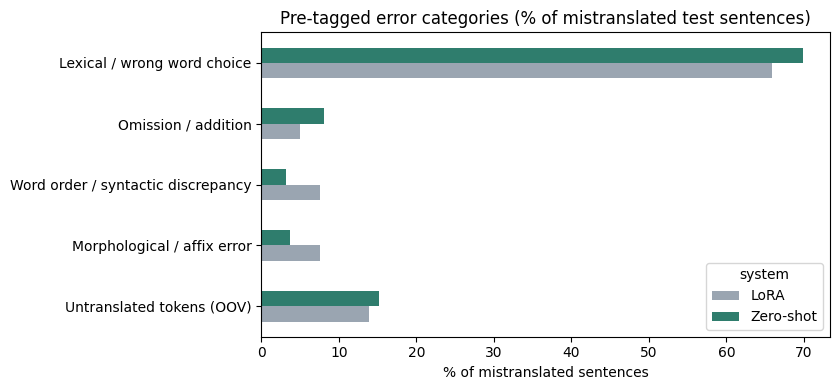

In [14]:
def profile(hyps_by_dir, label):
    rows = []
    for d in DIRECTIONS:
        n_exact = n_err = 0; cnt = collections.Counter()
        for src, ref, hyp in zip(SRCS[d], REFS[d], hyps_by_dir[d]):
            if norm_key(hyp) == norm_key(ref): n_exact += 1; continue
            if sent_chrf(hyp, ref) >= ERR_CHRF_MAX: continue
            n_err += 1; cnt[diagnose(src, ref, hyp)["auto_category"]] += 1
        rows.append({"system": label, "direction": DIR_LABEL(d), "n": len(REFS[d]), "exact match %": 100 * n_exact / len(REFS[d]),
                     "mistranslated n": n_err, **{c: cnt.get(c, 0) for c in CAT_LIST[:5]}})
    return pd.DataFrame(rows)

prof = pd.concat([profile(ZS, "Zero-shot"), profile(FT, "LoRA")], ignore_index=True)
display(prof.round(1)); prof.to_csv(f"{OUT_DIR}/error_profile_auto.csv", index=False)
tot = prof.groupby("system")[CAT_LIST[:5]].sum(); tot_pct = (tot.T / tot.sum(axis=1)).T * 100
display(tot_pct.round(1))
ax = tot_pct.T.plot.barh(figsize=(8.5, 4), color=["#9aa5b1", "#2f7d6d"], title="Pre-tagged error categories (% of mistranslated test sentences)")
ax.set_xlabel("% of mistranslated sentences"); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figures/error_profile_auto.png", dpi=150); plt.show()

### 6c. Summary of the manual review (run after you filled `final_category`)
Set `UPLOAD_REVIEWED = True` to upload your edited `error_analysis_sample.xlsx` (or `.csv`) in Colab, or place it next to the notebook as `error_analysis_reviewed.xlsx`. If no reviewed file is found the summary falls back to the **pre-tagged** categories and says so.

Category source: AUTOMATIC PRE-TAG ONLY — NOT YET REVIEWED BY A HUMAN


,sentences,%
category,,
Untranslated tokens (OOV),7,14.0
Morphological / affix error,5,10.0
Word order / syntactic discrepancy,4,8.0
Omission / addition,2,4.0
Lexical / wrong word choice,32,64.0
Acceptable alternative (not a real error),0,0.0


direction,bcl_North → bcl_South,bcl_North → eng,bcl_South → bcl_North,bcl_South → eng,eng → bcl_North,eng → bcl_South
category,,,,,,
Untranslated tokens (OOV),2,0,5,0,0,0
Morphological / affix error,1,1,0,0,1,2
Word order / syntactic discrepancy,0,0,0,0,2,2
Omission / addition,0,1,0,1,0,0
Lexical / wrong word choice,5,7,3,7,6,4
Acceptable alternative (not a real error),0,0,0,0,0,0


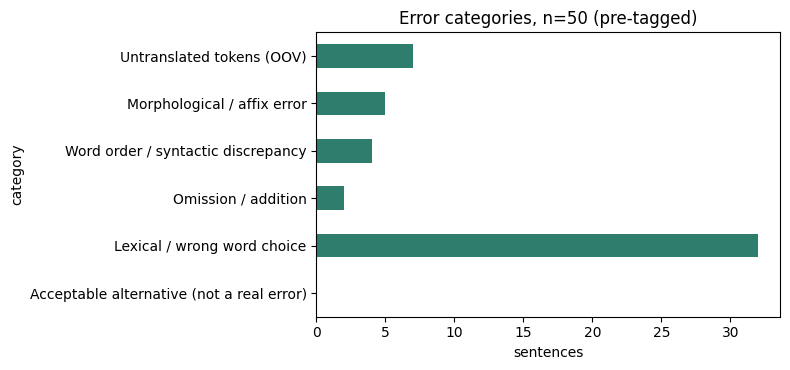


One illustrative example per category (for the report / defense slides):

[Untranslated tokens (OOV)]  bcl_South → bcl_North
  src: Linigan mo ang lamesa mo pagkatapos mong magkaon.
  ref: Limpyahan mo yang imong lamesa pakatapos mo magkaon ning snack.
  hyp: Linigan mo yu lamesa pagkatapos magkaon.
  note: copied from source: linigan, pagkatapos // near-miss: 'pagkatapos' vs ref 'pakatapos' (prefix pag- → pa-)

[Morphological / affix error]  bcl_North → eng
  src: Ikan ka man ning mga gwantes na pangtinaman?
  ref: Do you also have gardening gloves?
  hyp: Do you have garden ornaments?
  note: near-miss: 'garden' vs ref 'gardening' (suffix -∅ → -ing)

[Word order / syntactic discrepancy]  eng → bcl_North
  src: Rest well tonight after a long walk.
  ref: Pahingaro ka na nintong gabi pakatapos ning harawig na pagpanaw.
  hyp: Magdiskanso ka ning turtor nintong gabi pakatapos maglakaw.
  note: 1 correct word(s) in wrong position

[Omission / addition]  bcl_North → eng
  src: Dunggon mo

In [15]:
UPLOAD_REVIEWED = False
rev_path = next((p for p in ("error_analysis_reviewed.xlsx", "error_analysis_reviewed.csv") if os.path.exists(p)), None)
if UPLOAD_REVIEWED and IN_COLAB:
    up = files.upload(); rev_path = list(up.keys())[0]
if rev_path:
    rev = pd.read_excel(rev_path, sheet_name="errors") if rev_path.endswith("xlsx") else pd.read_csv(rev_path)
    rev["final_category"] = rev["final_category"].fillna("").astype(str).str.strip()
    n_done = int((rev.final_category != "").sum()); assert set(rev.final_category) - {""} <= set(CAT_LIST), "unknown category label in final_category"
    work = rev
else:
    work, n_done = err_df.copy(), 0
work["category"] = np.where(work.final_category.astype(str).str.strip() != "", work.final_category, work.auto_category)
SUMMARY_SOURCE = (f"manual review ({n_done}/{len(work)} rows confirmed by a human)" if n_done else "AUTOMATIC PRE-TAG ONLY — NOT YET REVIEWED BY A HUMAN")
print("Category source:", SUMMARY_SOURCE)

err_sum = work.groupby("category").size().reindex(CAT_LIST).fillna(0).astype(int).to_frame("sentences"); err_sum["%"] = 100 * err_sum.sentences / err_sum.sentences.sum()
by_dir = pd.crosstab(work.category, work.direction).reindex(CAT_LIST).fillna(0).astype(int)
display(err_sum.round(1)); display(by_dir)
err_sum.to_csv(f"{OUT_DIR}/error_analysis_summary.csv"); by_dir.to_csv(f"{OUT_DIR}/error_analysis_by_direction.csv")
work.to_csv(f"{OUT_DIR}/error_analysis_final.csv", index=False, encoding="utf-8")
ax = err_sum.sentences.iloc[::-1].plot.barh(figsize=(8, 3.8), color="#2f7d6d", title=f"Error categories, n={len(work)} ({'reviewed' if n_done else 'pre-tagged'})")
ax.set_xlabel("sentences"); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figures/error_categories.png", dpi=150); plt.show()

print("\nOne illustrative example per category (for the report / defense slides):")
EXAMPLES = []
for c in CAT_LIST:
    g = work[work.category == c]
    if len(g):
        r = g.iloc[0]; EXAMPLES.append((c, r)); print(f"\n[{c}]  {r.direction}\n  src: {r.source}\n  ref: {r.reference}\n  hyp: {r.hypothesis}\n  note: {r.evidence}")

## 7. Auto-generated Phase 4 report + package
Writes `Phase4_Report.md` (all tables filled from the numbers above), `phase4_results.json`, and zips everything for download. The “Discussion” section contains only statements computed from the results; **add your own interpretation and the native-speaker review notes before the defense.**

In [16]:
def fmt(v):
    if isinstance(v, (float, np.floating)): return "" if np.isnan(v) else f"{v:.1f}"
    return str(v).replace("|", "\\|").replace("\n", " ")
def md_table(df, index=False):
    d = df.reset_index() if index else df
    L = ["| " + " | ".join(map(str, d.columns)) + " |", "|" + "|".join(["---"] * len(d.columns)) + "|"]
    for _, r in d.iterrows(): L.append("| " + " | ".join(fmt(v) for v in r) + " |")
    return "\n".join(L)

mean_row = bench_full[bench_full.Direction.str.startswith("MEAN")].iloc[0]
best_ft = num_tbl[num_tbl.system.str.startswith("LoRA")].sort_values("BLEU", ascending=False)
facts = [f"Averaged over the six directions, fine-tuning raised BLEU from {mean_row['BLEU zero-shot']:.1f} to {mean_row['BLEU LoRA']:.1f}, chrF++ from {mean_row['chrF++ zero-shot']:.1f} to {mean_row['chrF++ LoRA']:.1f}, and lowered TER from {mean_row['TER zero-shot']:.1f} to {mean_row['TER LoRA']:.1f}.",
         f"Best direction by BLEU: {best_ft.iloc[0].direction} ({best_ft.iloc[0].BLEU:.1f}); weakest: {best_ft.iloc[-1].direction} ({best_ft.iloc[-1].BLEU:.1f}).",
         f"The paired bootstrap found LoRA better than zero-shot in {int((bench_tbl[['p(BLEU)','p(chrF++)','p(TER)']] < 0.05).sum().sum())} of {3*len(DIRECTIONS)} direction×metric comparisons at p < 0.05.",
         f"Mean test BLEU {mean_row['BLEU LoRA']:.1f} vs. mean validation BLEU {mean_row['val BLEU (LoRA)']:.1f} (difference {mean_row['BLEU LoRA']-mean_row['val BLEU (LoRA)']:+.1f}); each direction's 95 % CI half-width is about ±3–4 BLEU with 235 sentences, so differences smaller than that are not reliable."]
for _, c in copy_tbl.iterrows():
    f = num_tbl[(num_tbl.direction == c.direction) & num_tbl.system.str.startswith("LoRA")].iloc[0]
    facts.append(f"{c.direction}: LoRA chrF++ {f['chrF++']:.1f} vs. {c['chrF++']:.1f} for simply copying the source (BLEU {f.BLEU:.1f} vs. {c.BLEU:.1f}).")
b_rows = lat_summary if "lat_summary" in globals() else None
if b_rows is not None:
    ok = lat_summary[lat_summary.mean_ms < LATENCY_TARGET_MS]
    facts.append("Latency: " + "; ".join(f"{r.variant.split(':')[0]}/{r['mode']} {r.mean_ms:.0f} ms mean (p95 {r.p95_ms:.0f})" for _, r in lat_summary.iterrows()) +
                 f". Configurations under the {LATENCY_TARGET_MS} ms mean target: " + (", ".join(f"{r.variant.split(':')[0]}/{r['mode']}" for _, r in ok.iterrows()) or "none") + ".")
facts.append(f"Error categories ({SUMMARY_SOURCE}): " + "; ".join(f"{c} {int(n)}" for c, n in err_sum.sentences.items()) + ".")

R = []
R.append("# Phase 4 Report — Quantitative Evaluation & Error Analysis\n")
R.append(f"*Northern (Pandan) / Southern (Virac) Catanduanes Bikol ↔ English · NLLB-200-distilled-600M + LoRA (r={meta.get('lora',{}).get('r','?')}, α={meta.get('lora',{}).get('alpha','?')}, best epoch {meta.get('training',{}).get('best_epoch','?')})*\n")
R.append("## 1. Evaluation setup\n")
R.append(f"- **Held-out test set:** {len(test_rows)} aligned sentence trios from the Phase 1 leakage-grouped 70/15/15 split (seed {SEED}), i.e. {len(test_rows)} pairs in each of 6 directions. The test set was not used for training, early stopping or model selection.\n- **Systems:** zero-shot `{MODEL_NAME}` (un-tuned; Pandan→`tgl_Latn`, Virac→`war_Latn`, English→`eng_Latn`) vs. the same model with the LoRA adapter merged.\n- **Decoding:** beam {NUM_BEAMS}, max source length {MAX_LEN} tokens, max 96 new tokens, fp16 autocast.\n- **Metrics (SacreBLEU):** `{SIGS['BLEU']}`; `{SIGS['chrF++']}`; `{SIGS['TER']}`.\n- **Uncertainty:** {BOOT_N} paired bootstrap resamples over test sentences (95 % percentile intervals).\n")
R.append("## 2. Task 4.1 — Test-set metrics\n"); R.append(md_table(main_tbl) + "\n")
R.append("Copy-source reference for the dialect↔dialect directions:\n"); R.append(md_table(copy_tbl.round(1)) + "\n")
R.append("## 3. Task 4.2 — Benchmark: zero-shot vs. LoRA\n"); R.append(md_table(bench_full.round(2)) + "\n")
R.append("`Δ` = LoRA − zero-shot (for TER a negative Δ is an improvement). `p` = paired-bootstrap share of resamples in which LoRA was not better.\n")
R.append("![test scores](figures/test_zero_shot_vs_lora.png)\n")
R.append("### Latency (inference time per input length)\n")
if b_rows is not None:
    R.append(md_table(lat_summary.round(1)) + "\n"); R.append("Mean latency (ms) by source length (NLLB tokens):\n"); R.append(md_table(lat_by_len.reset_index()) + "\n"); R.append("![latency](figures/latency_by_length.png)\n")
else: R.append("*(latency section not run)*\n")
API_RES = globals().get("API_RES")
if API_RES is not None:
    R.append("### End-to-end check through the Phase 3 engine\n"); R.append(md_table(API_RES["table"].round(1)) + "\n"); R.append("Confidence score vs. quality:\n"); R.append(md_table(API_RES["confidence"].round(2)) + "\n")
R.append("## 4. Task 4.3 — Linguistic error analysis\n")
R.append(f"Sample: {len(work)} mistranslated LoRA outputs (exact-match excluded, sentence chrF++ < {ERR_CHRF_MAX:.0f}), stratified over the six directions, seed {SEED}. **Category source: {SUMMARY_SOURCE}.**\n")
R.append(md_table(err_sum.round(1), index=True) + "\n"); R.append(md_table(by_dir, index=True) + "\n"); R.append("![error categories](figures/error_categories.png)\n")
R.append("Illustrative examples:\n")
for c, r in EXAMPLES: R.append(f"- **{c}** ({r.direction})  \n  source: *{r.source}*  \n  reference: *{r.reference}*  \n  system: *{r.hypothesis}*  \n  note: {r.evidence}\n")
R.append("Heuristic profile over all mistranslated test sentences (zero-shot vs. LoRA):\n"); R.append(md_table(tot_pct.round(1), index=True) + "\n")
R.append("## 5. Discussion (computed statements — extend with your own interpretation)\n"); R.extend(f"- {f}" for f in facts)
R.append("\n### Limitations to state in the defense\n- 235 test sentences per direction → wide confidence intervals; the corpus is short, phrasebook-style sentences, so scores do not transfer to news or conversational text.\n- NLLB-200 has no Bikol tag: Pandan and Virac borrow the `tgl_Latn` / `war_Latn` tags, so the zero-shot baseline is a *proxy*, not a Bikol-aware model.\n- One reference per sentence: valid paraphrases are scored as errors (category “Acceptable alternative”).\n- Pandan and Virac share many words, so BLEU/chrF++ for dialect↔dialect translation must be read against the copy-source reference.\n- Error categories above are only as reliable as their review status stated in §4.\n")
open(f"{OUT_DIR}/Phase4_Report.md", "w", encoding="utf-8").write("\n".join(R))

def jsonable(o):
    if isinstance(o, dict): return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [jsonable(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if np.isnan(o) else float(o)
    if isinstance(o, (np.integer,)): return int(o)
    return o
res = {"signatures": SIGS, "boot_n": BOOT_N, "test_metrics": num_tbl.to_dict("records"), "copy_baseline": copy_tbl.to_dict("records"),
       "benchmark": bench_full.to_dict("records"), "error_summary": err_sum.reset_index().to_dict("records"), "error_category_source": SUMMARY_SOURCE,
       "latency_summary": lat_summary.to_dict("records") if b_rows is not None else None, "adapter_meta": meta, "facts": facts}
json.dump(jsonable(res), open(f"{OUT_DIR}/phase4_results.json", "w"), indent=1, ensure_ascii=False)
shutil.make_archive("phase4_outputs", "zip", OUT_DIR); print("Wrote:", sorted(os.listdir(OUT_DIR)), "-> phase4_outputs.zip")
if IN_COLAB: files.download("phase4_outputs.zip")

Wrote: ['Phase4_Report.md', 'benchmark_table.csv', 'error_analysis_by_direction.csv', 'error_analysis_final.csv', 'error_analysis_sample.csv', 'error_analysis_sample.xlsx', 'error_analysis_summary.csv', 'error_profile_auto.csv', 'figures', 'latency_by_length.csv', 'latency_raw.csv', 'latency_summary.csv', 'phase4_results.json', 'test_copy_baseline.csv', 'test_metrics_by_direction.csv', 'test_predictions.csv'] -> phase4_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>